# Final project: Intelligent Medical Image Classification
Alexa Rodríguez Méndez 2133921 - Thursday N4

José Omar de Anda Garza 2012643 - Tuesday N4

## 1. Load libraries

In [ ]:
import os
import json
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Configuration
Main hyperparameters. `MODEL_TYPE = "transfer"` uses InceptionV3 pretrained on ImageNet (stage 1: train only the head; stage 2: fine-tune the last layers). `"custom"` uses the custom CNN.

In [ ]:
SEED = 42
IMG_SIZE = (224, 224)       # uniform input size
BATCH_SIZE = 32
MODEL_TYPE = "transfer"     # "transfer" (InceptionV3) or "custom" (custom CNN)
EPOCHS = 12                 # stage 1
FINE_TUNE = True            # stage 2 (transfer only): fine-tuning
FINE_TUNE_EPOCHS = 10
FINE_TUNE_LAYERS = 40       # how many final InceptionV3 layers are unfrozen
USE_AUGMENTATION = True     # light flips, rotations and zoom
USE_COLOR_AUG = True        # color/grayscale variations (robustness to other cameras)
TARGET_SPECIFICITY = 0.85   # minimum specificity when choosing the threshold on validation

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

## 3. Load data
The Kaggle dataset (`mos3santos/breast-cancer-diagnosis`) is downloaded with `kagglehub`. If the download fails, download the .zip from Kaggle, upload it to Colab, unzip it and assign the path to `dataset_path`.

In [ ]:
!pip install -q kagglehub
import kagglehub

dataset_path = kagglehub.dataset_download("mos3santos/breast-cancer-diagnosis")
print("Dataset downloaded to:", dataset_path)

In [ ]:
# Look for the "Dados" folder; if it does not exist, the downloaded root is used
DATA_DIR = dataset_path
for root, dirs, files in os.walk(dataset_path):
    if os.path.basename(root).lower() == "dados":
        DATA_DIR = root
        break
print("Data folder:", DATA_DIR, "\n")

# Folder structure (3 levels) and file types
for root, dirs, files in os.walk(DATA_DIR):
    depth = root[len(DATA_DIR):].count(os.sep)
    if depth <= 2:
        exts = Counter(os.path.splitext(f)[1].lower() for f in files)
        print("  " * depth + os.path.basename(root) + "/", dict(exts))

Data folder: /kaggle/input/breast-cancer-diagnosis/Dados 

Dados/ {'': 3, '.csv': 2, '.ods': 1}
  Imagens/ {}
    PACIENTE_0048/ {'.jpg': 27}
    PACIENTE_0107/ {'.jpg': 27}
    PACIENTE_0220/ {'.jpg': 27}
    PACIENTE_0273/ {'.jpg': 27}
    PACIENTE_0218/ {'.jpg': 27}
    PACIENTE_0190/ {'.jpg': 27}
    PACIENTE_0199/ {'.jpg': 27}
    PACIENTE_0244/ {'.jpg': 27}
    PACIENTE_0384/ {'.jpg': 27}
    PACIENTE_0170/ {'.jpg': 27}
    PACIENTE_0245/ {'.jpg': 27}
    PACIENTE_0090/ {'.jpg': 27}
    PACIENTE_0208/ {'.jpg': 27}
    PACIENTE_0130/ {'.jpg': 27}
    PACIENTE_0200/ {'.jpg': 27}
    PACIENTE_0061/ {'.jpg': 27}
    PACIENTE_0217/ {'.jpg': 27}
    PACIENTE_0016/ {'.jpg': 26}
    PACIENTE_0247/ {'.jpg': 1}
    PACIENTE_0115/ {'.jpg': 27}
    PACIENTE_0146/ {'.jpg': 27}
    PACIENTE_0125/ {'.jpg': 27}
    PACIENTE_0169/ {'.jpg': 27}
    PACIENTE_0080/ {'.jpg': 26}
    PACIENTE_0087/ {'.jpg': 27}
    PACIENTE_0328/ {'.jpg': 29}
    PACIENTE_0363/ {'.jpg': 30}
    PACIENTE_0398/ {'.jpg':

## 4. Data preprocessing
### 4.1 Labels, image loading and cleaning
The images are in `Dados/Imagens/PACIENTE_XXXX/` and each patient's diagnosis comes from `tabulares.csv` (column `Diagnosis`). The folder is matched to the patient ID. Patients with an `unknown` diagnosis are excluded.
**Image discard criteria:** corrupted or unreadable files, and shorter side below 32 px.

In [ ]:
VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp"}
MIN_SIDE = 32

# --- Diagnosis per patient ---
tab = pd.read_csv(os.path.join(DATA_DIR, "tabulares.csv"), sep=None, engine="python")
tab["Diagnosis"] = tab["Diagnosis"].astype(str).str.strip().str.lower()
print("Diagnoses in tabulares.csv:")
print(tab["Diagnosis"].value_counts(), "\n")

NEGATIVE_DIAG = {"healthy"}           # healthy
EXCLUDE_DIAG = {"unknown", "nan"}     # no confirmed diagnosis: excluded
tab = tab[~tab["Diagnosis"].isin(EXCLUDE_DIAG)].drop_duplicates("ID").copy()
tab["label"] = (~tab["Diagnosis"].isin(NEGATIVE_DIAG)).astype(int)   # 1 = pathological
print("Considered PATHOLOGICAL (1):", sorted(set(tab.loc[tab.label == 1, "Diagnosis"])))
print("Considered HEALTHY (0):", sorted(set(tab.loc[tab.label == 0, "Diagnosis"])), "\n")

NEGATIVE_CLASS, POSITIVE_CLASS = "healthy", "pathological"
patient_label = dict(zip(tab["ID"].astype(int), tab["label"]))

# --- Image loading and cleaning ---
IMG_DIR = os.path.join(DATA_DIR, "Imagens")
rows, discarded = [], 0
for folder in sorted(os.listdir(IMG_DIR)):
    try:
        pid = int(folder.split("_")[-1])          # PACIENTE_0001 -> 1
    except ValueError:
        continue
    if pid not in patient_label:                   # patient without diagnosis (unknown)
        continue
    fdir = os.path.join(IMG_DIR, folder)
    for f in sorted(os.listdir(fdir)):
        if os.path.splitext(f)[1].lower() not in VALID_EXT:
            continue
        path = os.path.join(fdir, f)
        try:
            with Image.open(path) as im:
                im.verify()                        # detects corrupted files
            with Image.open(path) as im:
                w, h = im.size
            if min(w, h) < MIN_SIDE:
                raise ValueError("image too small")
            rows.append((pid, path, patient_label[pid]))
        except Exception:
            discarded += 1

df = pd.DataFrame(rows, columns=["pid", "path", "label"])
print("Valid images:", len(df), "| discarded:", discarded)
print("Patients with images:", df["pid"].nunique())
print("Images per class:", df["label"].map({0: NEGATIVE_CLASS, 1: POSITIVE_CLASS}).value_counts().to_dict())

Diagnoses in tabulares.csv:
Diagnosis
healthy    178
sick       100
unknown      5
Name: count, dtype: int64 

Considered PATHOLOGICAL (1): ['sick']
Considered HEALTHY (0): ['healthy'] 

Valid images: 7245 | discarded: 0
Patients with images: 278
Images per class: {'healthy': 4510, 'pathological': 2735}


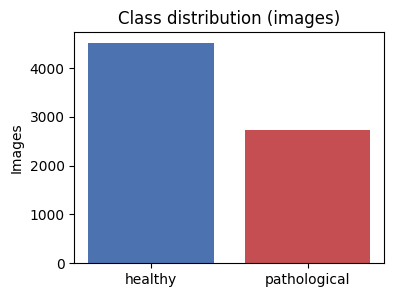

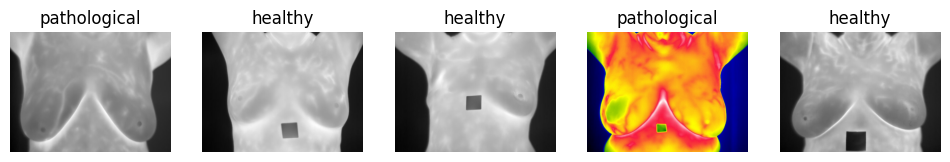

In [ ]:
# Class distribution and examples
counts = df["label"].map({0: NEGATIVE_CLASS, 1: POSITIVE_CLASS}).value_counts()
plt.figure(figsize=(4, 3))
plt.bar(counts.index, counts.values, color=["#4c72b0", "#c44e52"])
plt.title("Class distribution (images)"); plt.ylabel("Images")
plt.show()

plt.figure(figsize=(12, 3))
for i, idx in enumerate(random.sample(range(len(df)), 5)):
    plt.subplot(1, 5, i + 1)
    plt.imshow(Image.open(df.iloc[idx]["path"]).convert("RGB"))
    plt.title(NEGATIVE_CLASS if df.iloc[idx]["label"] == 0 else POSITIVE_CLASS)
    plt.axis("off")
plt.show()

### 4.2 80 % training / 20 % test split (by patient)
There are several images per patient. If the split were done per image, photos of the same patient would end up in both training and test (*data leakage*) and inflate the accuracy. That is why the 80/20 split is done **by patient** (stratified by diagnosis). 15 % of the 80 % training set is set aside for validation.

In [ ]:
patients = df.groupby("pid")["label"].first().reset_index()

train_p, test_p = train_test_split(patients, test_size=0.20, stratify=patients["label"], random_state=SEED)
train_p, val_p = train_test_split(train_p, test_size=0.15, stratify=train_p["label"], random_state=SEED)

def subset(pids):
    s = df[df["pid"].isin(pids)]
    return s["path"].values, s["label"].values

train_paths, train_labels = subset(train_p["pid"])
val_paths, val_labels = subset(val_p["pid"])
test_paths, test_labels = subset(test_p["pid"])

print(f"Patients -> train: {len(train_p)} | val: {len(val_p)} | test: {len(test_p)}")
print(f"Images   -> train: {len(train_paths)} | val: {len(val_paths)} | test: {len(test_paths)}")
print("Pathological in test:", int(test_labels.sum()), "of", len(test_labels))

Patients -> train: 188 | val: 34 | test: 56
Images   -> train: 4925 | val: 878 | test: 1442
Pathological in test: 563 of 1442


### 4.3 Resizing and normalization
All images are converted to RGB, resized to 224×224 and their pixels are scaled from [0, 255] to [0, 1]. **This same function is used later for the new images** (inference).

In [ ]:
def load_and_preprocess(path):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0      # normalization to [0, 1]
    return img

def color_augment(img):
    # Training only: simulates other palettes/cameras (includes grayscale)
    gray = tf.image.grayscale_to_rgb(tf.image.rgb_to_grayscale(img))
    img = tf.cond(tf.random.uniform([]) < 0.3, lambda: gray, lambda: img)
    img = tf.image.random_saturation(img, 0.6, 1.4)
    img = tf.image.random_brightness(img, 0.08)
    img = tf.image.random_contrast(img, 0.8, 1.2)
    return tf.clip_by_value(img, 0.0, 1.0)

def make_dataset(p, l, training=False):
    ds = tf.data.Dataset.from_tensor_slices((p, l))
    if training:
        ds = ds.shuffle(len(p), seed=SEED)
    ds = ds.map(lambda x, y: (load_and_preprocess(x), tf.cast(y, tf.float32)),
                num_parallel_calls=tf.data.AUTOTUNE)
    if training and USE_COLOR_AUG:
        ds = ds.map(lambda x, y: (color_augment(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds   = make_dataset(val_paths, val_labels)
test_ds  = make_dataset(test_paths, test_labels)      # no shuffle: keeps the order

## 5. Model selection and training
**Custom CNN (`custom`):** 4 `Conv2D` + `MaxPooling2D` blocks, `Dropout` to reduce overfitting and a sigmoid output (binary classification). It is lightweight and fast to train.
**Transfer learning (`transfer`):** InceptionV3 with frozen ImageNet weights; it leverages visual features already learned from millions of images, which is useful when the medical dataset is small.

In [ ]:
def build_augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.1),
    ], name="augmentation")

def build_custom_cnn():
    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = build_augmentation()(inputs) if USE_AUGMENTATION else inputs
    for filters in (32, 64, 128, 128):
        x = layers.Conv2D(filters, (3, 3), activation="relu", padding="same")(x)
        x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.25)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name="custom_cnn")

def build_transfer_model():
    base = keras.applications.InceptionV3(include_top=False, weights="imagenet",
                                          input_shape=IMG_SIZE + (3,))
    base.trainable = False
    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = build_augmentation()(inputs) if USE_AUGMENTATION else inputs
    x = layers.Rescaling(2.0, offset=-1.0)(x)      # [0,1] -> [-1,1], range expected by InceptionV3
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name="inceptionv3_transfer")

model = build_custom_cnn() if MODEL_TYPE == "custom" else build_transfer_model()
model.summary()

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "inceptionv3_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 5, 5, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,804,833 (83.18 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [ ]:
def compile_model(lr):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc")]
    )

# Class weights to compensate for the imbalance
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=train_labels)
class_weight = {0: cw[0], 1: cw[1]}
print("Class weights:", class_weight)

def callbacks():
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)]

# --- Stage 1 ---
compile_model(1e-3)
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                    class_weight=class_weight, callbacks=callbacks())
hist = {k: list(v) for k, v in history.history.items()}

# --- Stage 2: fine-tuning (transfer learning only) ---
if MODEL_TYPE == "transfer" and FINE_TUNE:
    base_model = [l for l in model.layers if isinstance(l, keras.Model) and l.name != "augmentation"][0]
    base_model.trainable = True
    for l in base_model.layers[:-FINE_TUNE_LAYERS]:
        l.trainable = False
    for l in base_model.layers:                       # BatchNorm stays frozen
        if isinstance(l, layers.BatchNormalization):
            l.trainable = False
    compile_model(1e-5)                               # low learning rate
    history2 = model.fit(train_ds, validation_data=val_ds, epochs=FINE_TUNE_EPOCHS,
                         class_weight=class_weight, callbacks=callbacks())
    for k, v in history2.history.items():
        hist[k] += list(v)

Class weights: {0: np.float64(0.798734998378203), 1: np.float64(1.3368621064060804)}
Epoch 1/12
154/154 ━━━━━━━━━━━━━━━━━━━━ 45s 185ms/step - accuracy: 0.7927 - auc: 0.8646 - loss: 0.4432 - val_accuracy: 0.8303 - val_auc: 0.8958 - val_loss: 0.3779 - learning_rate: 0.0010
Epoch 2/12
154/154 ━━━━━━━━━━━━━━━━━━━━ 24s 130ms/step - accuracy: 0.8589 - auc: 0.9285 - loss: 0.3283 - val_accuracy: 0.8599 - val_auc: 0.8926 - val_loss: 0.3759 - learning_rate: 0.0010
Epoch 3/12
154/154 ━━━━━━━━━━━━━━━━━━━━ 22s 142ms/step - accuracy: 0.8784 - auc: 0.9434 - loss: 0.2952 - val_accuracy: 0.8519 - val_auc: 0.8860 - val_loss: 0.3589 - learning_rate: 0.0010
Epoch 4/12
154/154 ━━━━━━━━━━━━━━━━━━━━ 20s 131ms/step - accuracy: 0.8808 - auc: 0.9469 - loss: 0.2855 - val_accuracy: 0.8405 - val_auc: 0.8925 - val_loss: 0.3616 - learning_rate: 0.0010
Epoch 5/12
154/154 ━━━━━━━━━━━━━━━━━━━━ 22s 140ms/step - accuracy: 0.8849 - auc: 0.9498 - loss: 0.2777 - val_accuracy: 0.8474 - val_auc: 0.8978 - val_loss: 0.3436 - le

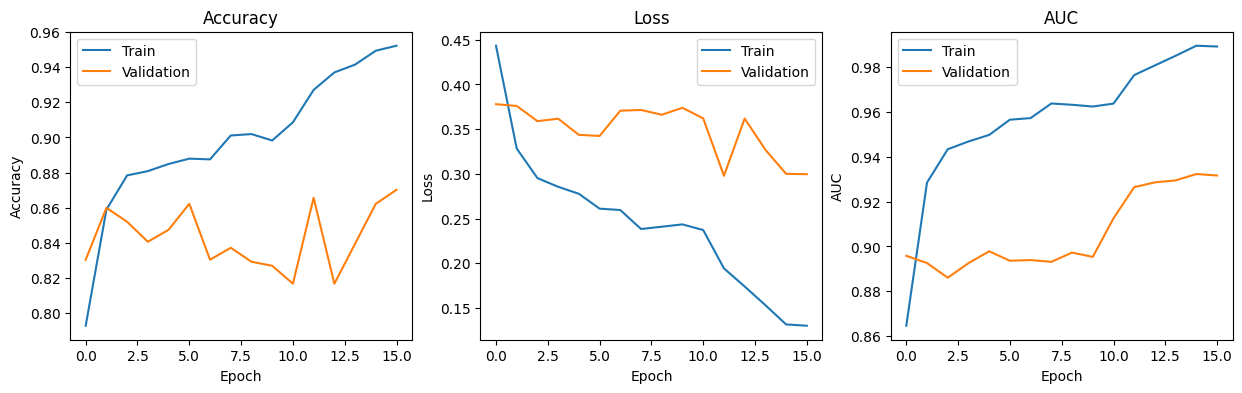

In [ ]:
plt.figure(figsize=(15, 4))
for j, (m, title) in enumerate([("accuracy", "Accuracy"), ("loss", "Loss"), ("auc", "AUC")]):
    plt.subplot(1, 3, j + 1)
    plt.plot(hist[m], label="Train")
    plt.plot(hist["val_" + m], label="Validation")
    plt.xlabel("Epoch"); plt.ylabel(title); plt.legend(); plt.title(title)
plt.show()

### 5.1 Decision threshold
With 0.5 the model may be too conservative and miss pathological cases (false negatives). The threshold is chosen with the **validation set** (never the test set): the one that gives the **highest sensitivity** while keeping a minimum specificity (`TARGET_SPECIFICITY`).

In [ ]:
val_probs = model.predict(val_ds).ravel()
fpr, tpr, thr = roc_curve(val_labels, val_probs)
spec = 1 - fpr

ok = np.where((spec >= TARGET_SPECIFICITY) & np.isfinite(thr))[0]
best = ok[np.argmax(tpr[ok])] if len(ok) else np.argmax(tpr - fpr)
THRESHOLD = float(thr[best]) if np.isfinite(thr[best]) else 0.5

print(f"Validation AUC: {roc_auc_score(val_labels, val_probs):.4f}")
print(f"Chosen threshold: {THRESHOLD:.3f}")
print(f"On validation with that threshold -> sensitivity: {tpr[best]:.3f} | specificity: {spec[best]:.3f}")

28/28 ━━━━━━━━━━━━━━━━━━━━ 7s 164ms/step
Validation AUC: 0.9264
Chosen threshold: 0.394
On validation with that threshold -> sensitivity: 0.812 | specificity: 0.869


## 6. Model testing
The model is evaluated on the 20 % test set. In a clinical context:
- **Sensitivity (recall of the positive class):** minimizes false negatives (undetected pathological cases).
- **Specificity (recall of the negative class):** avoids unnecessary treatment caused by false positives.

In [ ]:
probs = model.predict(test_ds).ravel()
y_true = np.array(test_labels)
print(f"ROC AUC (test): {roc_auc_score(y_true, probs):.4f}\n")

def report(th, title):
    preds = (probs >= th).astype(int)
    cm = confusion_matrix(y_true, preds)
    tn, fp, fn, tp = cm.ravel()
    print("=" * 60)
    print(title)
    print(f"Accuracy: {accuracy_score(y_true, preds):.4f} ({accuracy_score(y_true, preds)*100:.2f}%)\n")
    print(classification_report(y_true, preds, target_names=[NEGATIVE_CLASS, POSITIVE_CLASS], digits=4, zero_division=0))
    print(f"Sensitivity (recall of '{POSITIVE_CLASS}'): {tp/(tp+fn):.4f}")
    print(f"Specificity (recall of '{NEGATIVE_CLASS}'): {tn/(tn+fp):.4f}")
    print(f"False negatives: {fn} | False positives: {fp}\n")
    return cm

cm_default = report(0.5, "Standard threshold 0.5")
cm = report(THRESHOLD, f"Threshold chosen on validation ({THRESHOLD:.3f})")

46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 147ms/step
ROC AUC (test): 0.9116

Standard threshold 0.5
Accuracy: 0.8315 (83.15%)

              precision    recall  f1-score   support

     healthy     0.8706    0.8498    0.8601       879
pathological     0.7740    0.8028    0.7881       563

    accuracy                         0.8315      1442
   macro avg     0.8223    0.8263    0.8241      1442
weighted avg     0.8329    0.8315    0.8320      1442

Sensitivity (recall of 'pathological'): 0.8028
Specificity (recall of 'healthy'): 0.8498
False negatives: 111 | False positives: 132

Threshold chosen on validation (0.394)
Accuracy: 0.8051 (80.51%)

              precision    recall  f1-score   support

     healthy     0.8853    0.7816    0.8302       879
pathological     0.7117    0.8419    0.7714       563

    accuracy                         0.8051      1442
   macro avg     0.7985    0.8117    0.8008      1442
weighted avg     0.8175    0.8051    0.8072      1442

Sensitivity (recall of 'patholo

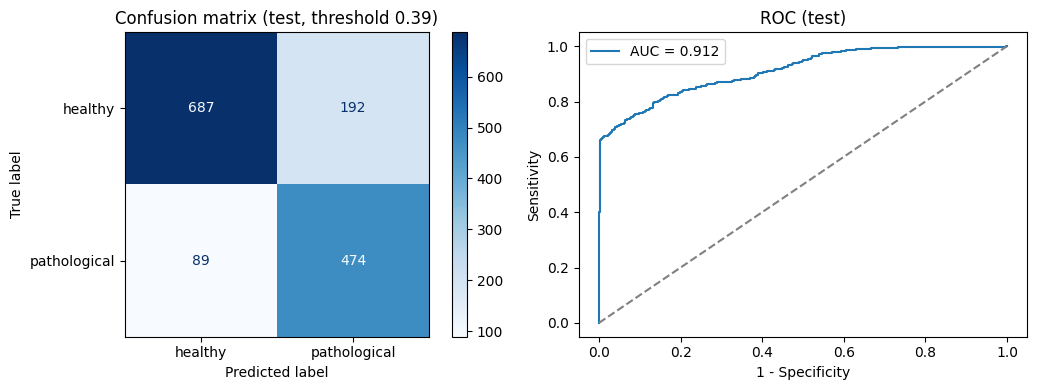

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(cm, display_labels=[NEGATIVE_CLASS, POSITIVE_CLASS]).plot(cmap="Blues", values_format="d", ax=ax[0])
ax[0].set_title(f"Confusion matrix (test, threshold {THRESHOLD:.2f})")

fpr_t, tpr_t, _ = roc_curve(y_true, probs)
ax[1].plot(fpr_t, tpr_t, label=f"AUC = {roc_auc_score(y_true, probs):.3f}")
ax[1].plot([0, 1], [0, 1], "--", color="gray")
ax[1].set_xlabel("1 - Specificity"); ax[1].set_ylabel("Sensitivity"); ax[1].set_title("ROC (test)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 7. Model deployment
### 7.1 Save the model (.h5)

In [ ]:
MODEL_FILE = "breast_cancer_cnn.h5"
model.save(MODEL_FILE)

# Save the class mapping alongside the model
with open("class_mapping.json", "w") as f:
    json.dump({"negative": NEGATIVE_CLASS, "positive": POSITIVE_CLASS, "img_size": IMG_SIZE, "threshold": THRESHOLD}, f)

print("Model saved:", MODEL_FILE, f"({os.path.getsize(MODEL_FILE)/1e6:.1f} MB)")

# Download to your computer (Colab only)
try:
    from google.colab import files
    files.download(MODEL_FILE)
    files.download("class_mapping.json")
except Exception as e:
    print("Download manually from the Colab file panel.", e)

Model saved: breast_cancer_cnn.h5 (136.4 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 7.2 Inference with new images
Upload **at least 5 images that are not part of the original dataset** (same type of image as the dataset: same study/modality). They go through the same preprocessing (RGB, 224×224, [0,1] scale).

In [ ]:
loaded_model = keras.models.load_model(MODEL_FILE)   # the saved model is reloaded

from google.colab import files
uploaded = files.upload()
new_paths = list(uploaded.keys())
if len(new_paths) < 5:
    print("Upload at least 5 images to meet the requirement.")

Saving S3.jpg to S3.jpg
Saving S2.jpg to S2.jpg
Saving S1.jpg to S1.jpg
Saving N3.jpg to N3.jpg
Saving N2.jpg to N2.jpg
Saving N1-.jpg to N1-.jpg


S3.jpg: No pathology: 88.4% confidence | (pathology score 11.6%)
S2.jpg: Pathology Detected: 57.0% confidence | (pathology score 57.0%)
S1.jpg: Pathology Detected: 60.7% confidence | (pathology score 60.7%)
N3.jpg: No pathology: 95.6% confidence | (pathology score 4.4%)
N2.jpg: Pathology Detected: 52.4% confidence | (pathology score 52.4%)
N1-.jpg: No pathology: 86.9% confidence | (pathology score 13.1%)


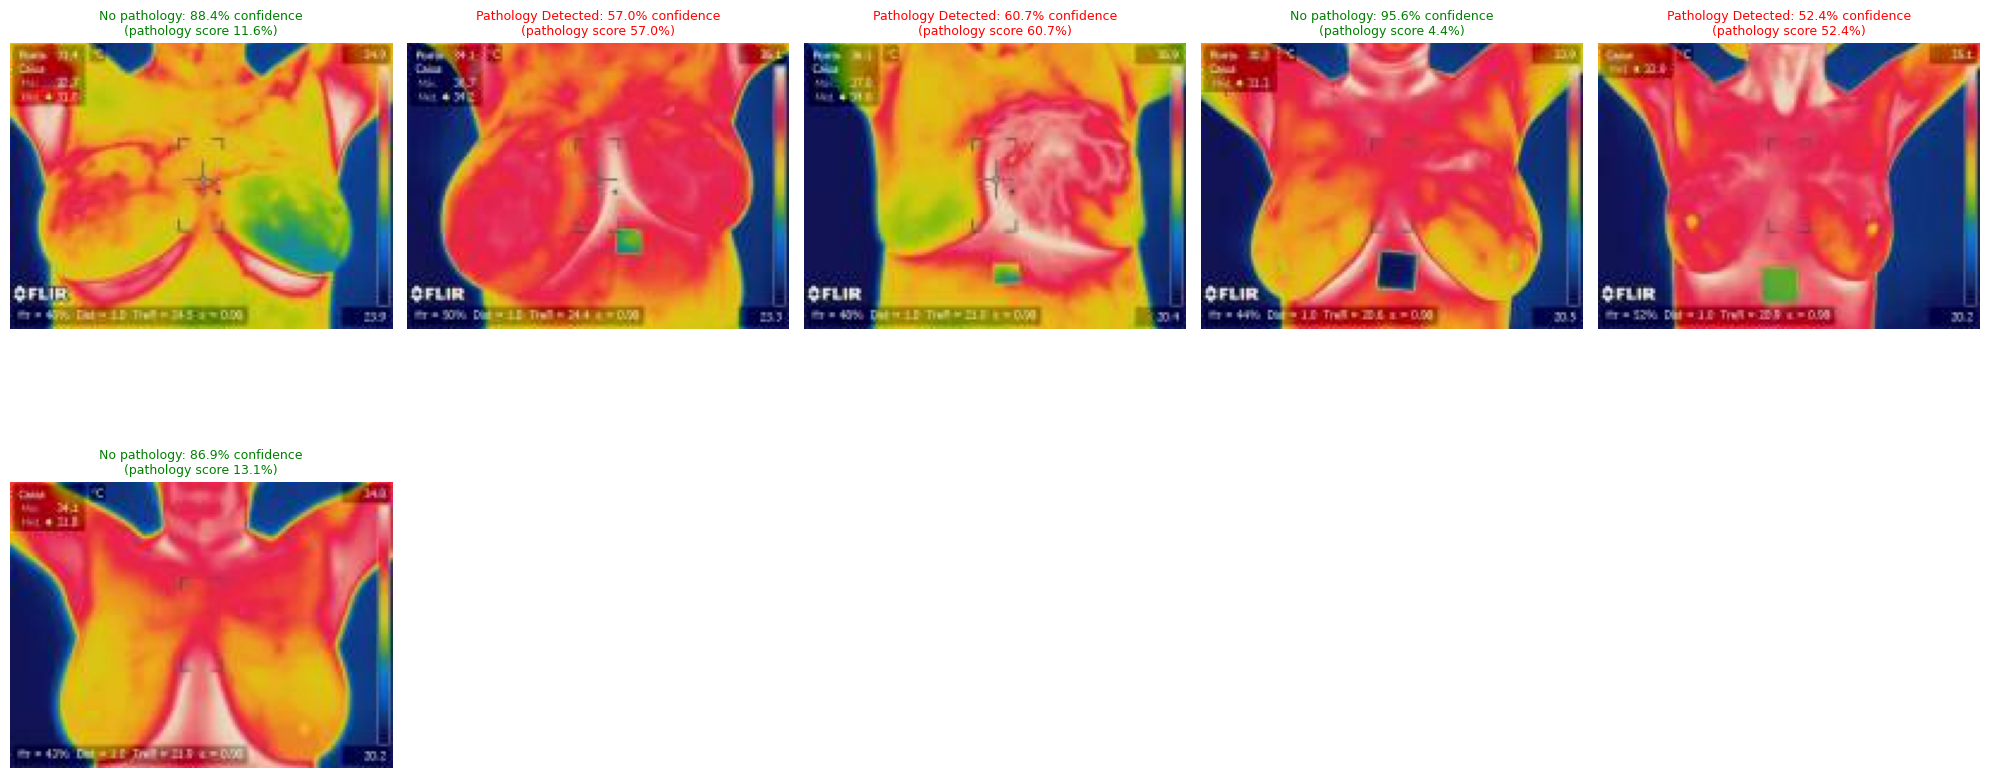

Validation: 11% of images in gray zone | accuracy outside it: 0.884


In [ ]:
BAND = 0.10   # indeterminate zone: THRESHOLD ± BAND (defined a priori, not tuned to these images)

def classify(prob):
    if abs(prob - THRESHOLD) < BAND:
        return "Indeterminate (borderline)", "orange", None
    if prob >= THRESHOLD:
        return "Pathology Detected", "red", prob          # confidence = pathology score
    return "No pathology", "green", 1 - prob              # confidence = 1 - score

n = len(new_paths); cols = min(n, 5); rows = int(np.ceil(n / cols))
plt.figure(figsize=(4 * cols, 4.8 * rows))

for i, p in enumerate(new_paths):
    img = load_and_preprocess(p)                          # same preprocessing
    prob = float(loaded_model.predict(img[None, ...], verbose=0)[0][0])
    label, color, conf = classify(prob)
    if conf is None:
        txt = f"{label}\nPathology score: {prob*100:.1f}% (threshold {THRESHOLD*100:.0f}%)"
    else:
        txt = f"{label}: {conf*100:.1f}% confidence\n(pathology score {prob*100:.1f}%)"
    plt.subplot(rows, cols, i + 1)
    plt.imshow(Image.open(p).convert("RGB"))
    plt.title(txt, fontsize=9, color=color); plt.axis("off")
    print(f"{os.path.basename(p)}: {txt.replace(chr(10), ' | ')}")
plt.tight_layout(); plt.show()

# Justification of the gray zone using VALIDATION (not the new images)
inb = np.abs(val_probs - THRESHOLD) < BAND
acc_out = ((val_probs >= THRESHOLD) == val_labels)[~inb].mean()
print(f"Validation: {inb.mean()*100:.0f}% of images in gray zone | accuracy outside it: {acc_out:.3f}")